# Measuring an impulse response without a sound card

`SimulatedFRFMeasure` replaces the sound card of `FRFMeasure` by a simulated measurement chain: a known system, a nonlinearity of the loudspeaker, background noise and quantization. The code of a real measurement runs unchanged, so it can be tried, taught and tested anywhere. Here the system is a synthetic room with a reverberation time of 1.2 s.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pytta

fs = 48000

The room: a statistical impulse response (Kuttruff's model) of a 300 m³ room with T = 1.2 s, 4 m from the source.

In [2]:
room = pytta.generate.stochastic_ir(1.2, 300, distance=4, samplingRate=fs, seed=1)
h = np.asarray(room.timeSignal[:, 0], dtype=float)

The excitation: an exponential sweep from 20 Hz to 20 kHz, with 1.5 s of silence after it so that the response of the room is recorded.

In [3]:
sweep = pytta.generate.sweep(freqMin=20, freqMax=20000, samplingRate=fs, fftDegree=18,
                             startMargin=0.05, stopMargin=1.5)

The measurement chain adds a small cubic nonlinearity (y = x + 0.05 x³), background noise 70 dB below full scale and a 24-bit quantization. The output is played 30 dB below full scale, as in a real measurement, so that the recording does not clip. `run()` plays the sweep through the chain and returns the deconvolved `ImpulsiveResponse`, as `FRFMeasure.run()` does with a sound card.

In [4]:
m = pytta.classes.SimulatedFRFMeasure(system=h, nonlinear=(1., 0., 0.05), noise=-70.,
                                      bits=24, seed=2, excitation=sweep, outputAmplification=-30,
                                      inChannels=[1], outChannels=[1], device=0)
measured = m.run()
ir = np.asarray(measured.IR.timeSignal[:, 0], dtype=float)

max output level (excitation) on channel [1]: -30.45 dBFS - ref.: 1 [FS]
max input level (excitation) on channel [1]: -20.66 dBFS - ref.: 1 [FS]


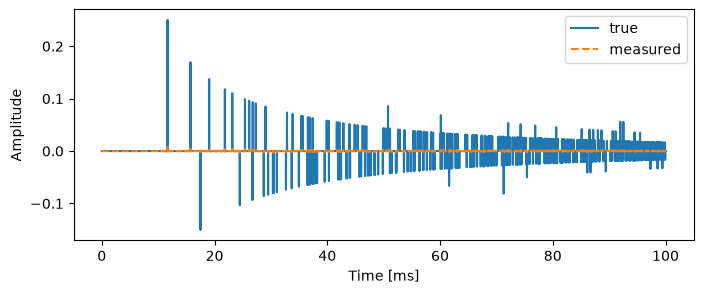

In [5]:
t = np.arange(4800) / fs
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t * 1e3, h[:4800], label='true')
ax.plot(t * 1e3, ir[:4800], '--', label='measured')
ax.set(xlabel='Time [ms]', ylabel='Amplitude')
ax.legend()
plt.show()

The room parameters of the measured response, in octave bands, against the reverberation time of the model.

In [6]:
ra = pytta.RoomAnalysis(pytta.SignalObj(ir[:int(1.6 * fs)], 'time', fs),
                        nthOct=1, minFreq=125, maxFreq=4000)
print('bands [Hz]', np.round(ra.bands))
print('T30   [s] ', np.round(ra.T30, 2), ' (model: 1.2 s)')
print('C80   [dB]', np.round(ra.C80, 2))

bands [Hz] [ 125.  250.  500. 1000. 2000. 4000.]
T30   [s]  [1.14 1.19 1.22 1.22 1.19 1.21]  (model: 1.2 s)
C80   [dB] [0.56 0.05 0.89 2.03 1.83 1.67]
